<a href="https://colab.research.google.com/github/Gagangowdatg/AI_LAB/blob/main/Week_09_1bm24cs098_folusing_resolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RESOLUTION STEPS:

R4: ~Human(Socrates)  [R3, R1]
R5: {}  [R4, R2]

Hence proved.



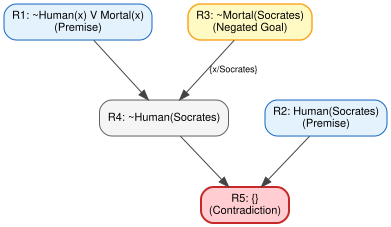

In [7]:
import re
from collections import deque
from graphviz import Digraph
from IPython.display import display


# ---------- PARSING ----------

def parse_literal(s):
    s = s.strip()
    neg = s.startswith("~")
    if neg:
        s = s[1:].strip()

    match = re.fullmatch(r'([A-Za-z_]\w*)\((.*?)\)', s)
    if not match:
        raise ValueError("Invalid literal: " + s)

    pred = match.group(1)
    args = tuple(x.strip() for x in match.group(2).split(","))
    if not args or any(not x for x in args):
        raise ValueError("Invalid arguments")

    return (neg, pred, args)


def parse_clause(s):
    if not s.strip():
        raise ValueError("Empty premise")
    return tuple(parse_literal(x) for x in s.split("|"))


# ---------- VARIABLE IDENTIFICATION & SUBSTITUTION ----------

def is_variable(x):
    return (len(x) == 1 and x.islower()) or x.startswith("?")


def apply_subst(x, subst):
    visited = set()
    while x in subst and x not in visited:
        visited.add(x)
        x = subst[x]
    return x


def unify(args1, args2):
    if len(args1) != len(args2):
        return None
    subst = {}
    for a, b in zip(args1, args2):
        a = apply_subst(a, subst)
        b = apply_subst(b, subst)
        if a == b:
            continue
        if is_variable(a):
            subst[a] = b
        elif is_variable(b):
            subst[b] = a
        else:
            return None
    return subst


def substitute(clause, subst):
    return tuple((neg, pred, tuple(apply_subst(x, subst) for x in args)) for neg, pred, args in clause)


def standardize(clause, number):
    mapping = {}
    result = []
    for neg, pred, args in clause:
        new_args = []
        for arg in args:
            if is_variable(arg):
                if arg not in mapping:
                    mapping[arg] = f"?{arg}_{number}"
                new_args.append(mapping[arg])
            else:
                new_args.append(arg)
        result.append((neg, pred, tuple(new_args)))
    return tuple(result)


def canonical_key(clause):
    mapping = {}
    result = []
    for neg, pred, args in clause:
        new_args = []
        for arg in args:
            if is_variable(arg):
                if arg not in mapping:
                    mapping[arg] = f"VAR{len(mapping)}"
                new_args.append(mapping[arg])
            else:
                new_args.append(arg)
        result.append((neg, pred, tuple(new_args)))
    return tuple(sorted(result))


def is_tautology(clause):
    for neg, pred, args in clause:
        if (not neg, pred, args) in clause:
            return True
    return False


# ---------- FORMATTING ----------

def format_literal(lit):
    neg, pred, args = lit
    sign = "~" if neg else ""
    clean_args = [re.sub(r'_\d+$', '', arg[1:]) if arg.startswith("?") else arg for arg in args]
    return f"{sign}{pred}({','.join(clean_args)})"


def format_clause(clause):
    return "{}" if not clause else " V ".join(format_literal(x) for x in clause)


def format_subst(subst):
    if not subst:
        return ""
    pairs = [f"{re.sub(r'_\d+$', '', k.lstrip('?'))}/{re.sub(r'_\d+$', '', v.lstrip('?'))}" for k, v in subst.items()]
    return "{" + ", ".join(pairs) + "}"


# ---------- RESOLUTION ----------

def resolve(c1, c2):
    results = []
    for i, (neg1, pred1, args1) in enumerate(c1):
        for j, (neg2, pred2, args2) in enumerate(c2):
            if pred1 != pred2 or neg1 == neg2:
                continue
            subst = unify(args1, args2)
            if subst is None:
                continue
            remaining = c1[:i] + c1[i + 1:] + c2[:j] + c2[j + 1:]
            new_clause = tuple(dict.fromkeys(substitute(remaining, subst)))
            if not is_tautology(new_clause):
                results.append((new_clause, subst))
    return results


# ---------- COLAB GRAPH ----------

def show_resolution_graph(empty_id, clauses, parents, goal_id):
    relevant = set()
    stack = [empty_id]
    while stack:
        node = stack.pop()
        if node not in relevant:
            relevant.add(node)
            if node in parents:
                p1, p2, _ = parents[node]
                stack.extend([p1, p2])

    dot = Digraph()
    dot.attr(rankdir="TB", splines="polyline", nodesep="0.5", ranksep="0.7")
    dot.attr("node", shape="box", style="rounded,filled", fontname="Helvetica", fontsize="11")
    dot.attr("edge", fontname="Helvetica", fontsize="9", color="#444444")

    for nid in sorted(relevant):
        label = f"R{nid + 1}: {format_clause(clauses[nid])}"
        if nid == empty_id:
            dot.node(str(nid), label + "\n(Contradiction)", fillcolor="#FFCDD2", color="#C62828", penwidth="2")
        elif nid == goal_id:
            dot.node(str(nid), label + "\n(Negated Goal)", fillcolor="#FFF9C4", color="#F9A825", penwidth="1.5")
        elif nid not in parents:
            dot.node(str(nid), label + "\n(Premise)", fillcolor="#E3F2FD", color="#1565C0")
        else:
            dot.node(str(nid), label, fillcolor="#F5F5F5", color="#616161")

    for nid in sorted(relevant):
        if nid in parents:
            p1, p2, subst = parents[nid]
            dot.edge(str(p1), str(nid), label=format_subst(subst))
            dot.edge(str(p2), str(nid))

    display(dot)


def run_resolution(premises_text, goal_text, max_steps=10000):
    kb = [parse_clause(line) for line in premises_text.strip().splitlines() if line.strip()]
    goal = parse_literal(goal_text.strip())
    if goal[0]:
        raise ValueError("ERROR: Goal must be positive.")

    negated_goal = (True, goal[1], goal[2])
    clauses = list(kb) + [(negated_goal,)]
    goal_id = len(clauses) - 1

    print("RESOLUTION STEPS:\n")
    known = {canonical_key(c) for c in clauses}
    parents = {}
    queue = deque([goal_id])
    processed = set()
    counter = 0

    while queue and counter < max_steps:
        current = queue.popleft()
        for other in range(len(clauses)):
            if current == other:
                continue
            pair = tuple(sorted((current, other)))
            if pair in processed:
                continue
            processed.add(pair)
            counter += 1

            c1 = standardize(clauses[current], counter * 2)
            c2 = standardize(clauses[other], counter * 2 + 1)

            for new_clause, subst in resolve(c1, c2):
                key = canonical_key(new_clause)
                if key in known:
                    continue
                known.add(key)
                new_id = len(clauses)
                clauses.append(new_clause)
                parents[new_id] = (current, other, subst)

                print(f"R{new_id + 1}: {format_clause(new_clause)}  [R{current + 1}, R{other + 1}]")

                if len(new_clause) == 0:
                    print("\nHence proved.\n")
                    show_resolution_graph(new_id, clauses, parents, goal_id)
                    return

                if len(new_clause) == 1:
                    queue.appendleft(new_id)
                else:
                    queue.append(new_id)

    print("\nHence not proved.")


# ==========================================
# PASTE YOUR PREMISES AND GOAL BELOW:
# ==========================================
premises = """
~Human(x) | Mortal(x)
Human(Socrates)
"""

goal = "Mortal(Socrates)"

run_resolution(premises, goal)